# Fourth down: go, kick or punt? A hands-on demo

This notebook runs in Google Colab with nothing to install by hand. In a few minutes on a CPU it

1. loads the project's precomputed **app bundle** (every number comes from the models and the solved game, evaluated once by `scripts/m7_build_app_bundle.py`),
2. answers one fourth-down situation two ways (one play ahead with bootstrap confidence, and the exactly solved game) and draws the **decision chart**, and
3. trains a small **tabular Q-learning** agent and measures its regret against the exact optimum.

The fitted models and the 2 GB solved game are not in the repository, so nothing here refits or re-solves anything; the bundle is the record of what they say.

## Setup

The next cell clones the repository and installs the package when it runs in Colab, and uses the local checkout otherwise.

**The clone works once the repository is public.** While it is private, use a GitHub fine-grained token with read access to this one repository, kept out of the notebook: in Colab open the key icon (Secrets) on the left, add a secret named `GH_TOKEN`, allow this notebook to read it, and set `USE_TOKEN = True` below. The token is read at run time with `google.colab.userdata` and never printed or saved. Never paste a token into a cell.

In [1]:
import os
import subprocess
import sys
from pathlib import Path

REPO = "github.com/Varkot-dev/fourth-and-rl.git"
USE_TOKEN = False  # True only while the repository is private (see the cell above)
IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    if not Path("fourth-and-rl").exists():
        url = f"https://{REPO}"
        if USE_TOKEN:
            from google.colab import userdata
            url = f"https://x-access-token:{userdata.get('GH_TOKEN')}@{REPO}"
        subprocess.run(["git", "clone", "--depth", "1", url], check=True, capture_output=True)
    os.chdir("fourth-and-rl")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".", "gymnasium"], check=True)
else:
    root = Path.cwd()
    while not (root / "pyproject.toml").exists():
        root = root.parent
    os.chdir(root)
sys.path.insert(0, str(Path("src").resolve()))  # importable without restarting the runtime
print("working in the repository folder:", Path.cwd().name)

working in the repository folder: fourth-and-rl


## 1. The app bundle

A grid of situations: 11 game clocks, scores from down 14 to up 14, every yard line, 1 to 15 yards to go, the opponent's timeouts in the last five minutes, and pregame spreads of -7, 0 and +7 (positive means the team with the ball is favoured). Nothing is interpolated.

In [2]:
from fourth_and_rl import app_bundle as ab

bundle = ab.load_bundle(os.environ.get("FOURTH_AND_RL_BUNDLE"))  # default: app/data/
meta = bundle.meta
print("built", meta["built_at"], "| replicates:", bundle.n_boot)
print("clocks:", [c["label"] for c in bundle.clocks])
print("one-step win-probability model:", meta["one_step"]["wp_model"],
      "fitted on", meta["one_step"]["wp_model_stamp"]["seasons"][0], "to",
      meta["one_step"]["wp_model_stamp"]["seasons"][-1])

built 2026-11-18T08:33:42+00:00 | replicates: 101
clocks: ['Q1 10:00', 'Q2 10:00', 'Q3 10:00', 'Q4 15:00', 'Q4 10:00', 'Q4 5:00', 'Q4 4:00', 'Q4 3:00', 'Q4 2:00', 'Q4 1:00', 'Q4 0:30']
one-step win-probability model: data/models/wp.joblib fitted on 2010 to 2023


## 2. One situation, two answers

Change the numbers and rerun. `seconds` must be one of the bundle's clocks (in seconds of game time left: 240 is 4:00 left in the fourth quarter), `score` is from the side of the team with the ball, `yardline_100` is the distance to the opponent's goal line (60 is your own 40).

In [3]:
situation = dict(seconds=240, score=4, yardline_100=60, ydstogo=2, opp_timeouts=3, spread=0)

cell = bundle.lookup(**situation)
one, exact = cell["one_step"], cell["exact"]
print(f"{cell['clock_label']}, score {situation['score']:+d}, fourth and {situation['ydstogo']} "
      f"at yardline_100 {situation['yardline_100']}")
print("\nOne play ahead (win probability, 90% bootstrap interval):")
for a in ab.ACTIONS:
    print(f"  {a:<11} {one['wp'][a]:.3f}  [{one['wp_lo'][a]:.3f}, {one['wp_hi'][a]:.3f}]")
print(f"  best: {one['best']}, {one['boot_counts'][one['best']]} of {bundle.n_boot} refits agree "
      f"-> {ab.CATEGORY_LABELS[one['category']]}")
print(f"  go minus the better kick: {100 * one['go_gain']:+.1f} points "
      f"[{100 * one['gain_lo']:+.1f}, {100 * one['gain_hi']:+.1f}]")
print("\nExact full game (identical teams, optimal play afterwards):")
for a in ab.ACTIONS:
    print(f"  {a:<11} {exact['wp'][a]:.3f}")
print(f"  best: {exact['best']}, go minus the better kick {100 * exact['go_gain']:+.1f} points")

Q4 4:00, score +4, fourth and 2 at yardline_100 60

One play ahead (win probability, 90% bootstrap interval):
  go          0.749  [0.726, 0.773]
  field_goal  nan  [nan, nan]
  punt        0.701  [0.684, 0.733]
  best: go, 100 of 101 refits agree -> Confident
  go minus the better kick: +4.8 points [+0.8, +6.4]

Exact full game (identical teams, optimal play afterwards):
  go          0.778
  field_goal  nan
  punt        0.714
  best: go, go minus the better kick +6.5 points


Why they can differ: the one-step engine looks one play ahead and then trusts a win-probability model fitted on real games, which carries real coaches' (more conservative) later choices; the exact solution plays the whole game for two identical teams that both play optimally. In the M4 notes, for this headline situation about 2.4 of the gap's points come from that assumption about later play.

### The decision chart for the whole situation

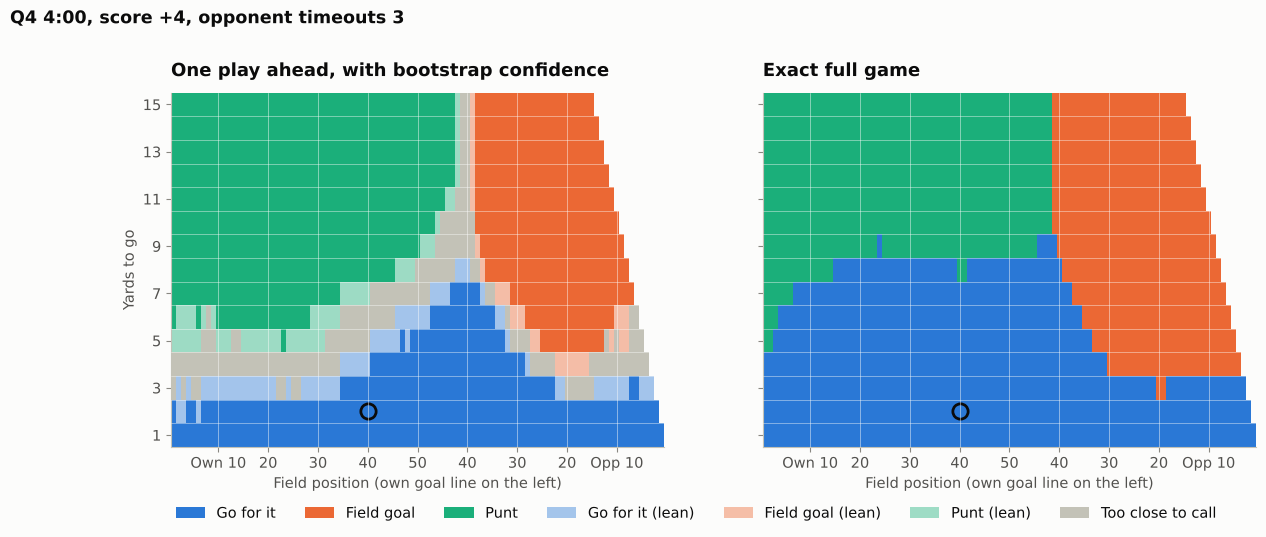

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from fourth_and_rl import decision, style

%matplotlib inline
style.apply()  # the project style (style.py selects a file backend; the line above undoes that)
chart = bundle.chart(situation["seconds"], situation["score"], situation["opp_timeouts"], situation["spread"])
names = np.array(["confident", "lean", "uncertain"], dtype=object)
category = np.where(chart["category"] >= 0, names[np.maximum(chart["category"], 0)], None)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
decision.draw_chart(axes[0], chart["best"].astype(float), category)
axes[0].set_title("One play ahead, with bootstrap confidence")
decision.draw_chart(axes[1], chart["exact_best"].astype(float))
axes[1].set_title("Exact full game")
for ax in axes:
    ax.set_xlabel("Field position (own goal line on the left)")
    ax.plot(100 - situation["yardline_100"], situation["ydstogo"], "o", mfc="none", mec=style.INK, ms=11, mew=2)
axes[0].set_ylabel("Yards to go")
fig.legend(handles=decision.chart_legend_handles(True), loc="lower center", ncol=7, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"{cell['clock_label']}, score {situation['score']:+d}, opponent timeouts {situation['opp_timeouts']}",
             x=0.01, y=1.06, ha="left", fontweight="bold")
plt.show()

## 3. Reinforcement learning against a known optimum

The real single-drive and end-game environments of M5 need the fitted tables, which are not in the repository. So this section uses the project's **toy drive model** (`fourth_and_rl.rl.toy.toy_drive`): a six-yard field with the same structure (fourth-down decisions between go, field goal and punt, touchdowns worth 7, field goals 3), small enough to solve exactly in milliseconds. That is what makes it useful for learning: we know the optimal value V* of every state, so the **regret** of a learned policy, the expected points per drive it gives up against the optimum, can be computed exactly instead of estimated.

Q-learning updates `Q(s, a) <- Q(s, a) + alpha * (r + max over a' of Q(s', a') - Q(s, a))` after every simulated decision, exploring with epsilon-greedy actions. The results for the real models are in `docs/notes/m5_rl.md`.

In [5]:
import time

from fourth_and_rl.rl import envs, toy
from fourth_and_rl.rl import evaluate as ev
from fourth_and_rl.rl.tabular import Schedule, td_control

model = toy.toy_drive(0)
env = envs.CompiledDrive(model)
baselines = ev.drive_baselines(model)
N_STEPS = 400_000
checkpoints = ev.log_checkpoints(N_STEPS, 30, first=200)

def regret_of(q, steps, episodes):
    return steps, ev.drive_regret(model, ev.greedy(q, model.allowed))

curves = {}
t0 = time.perf_counter()
for seed in (0, 1, 2):
    out = td_control(env, N_STEPS, seed=seed, algo="q_learning", schedule=Schedule(eps_decay_frac=0.6),
                     checkpoints=checkpoints, on_checkpoint=regret_of)
    curves[seed] = np.array(out["records"])
print(f"{model.n} fourth-down states; 3 runs of {N_STEPS:,} decisions in {time.perf_counter() - t0:.0f} s")
print({k: round(v, 3) for k, v in baselines.items()}, "<- regret of simple policies (points per drive)")
print("final Q-learning regret by seed:", {s: round(float(c[-1, 1]), 4) + 0.0 for s, c in curves.items()})

18 fourth-down states; 3 runs of 400,000 decisions in 2 s
{'never_go': 0.286, 'always_go': 0.722, 'random': 0.767} <- regret of simple policies (points per drive)
final Q-learning regret by seed: {0: 0.0, 1: 0.0, 2: 0.0}


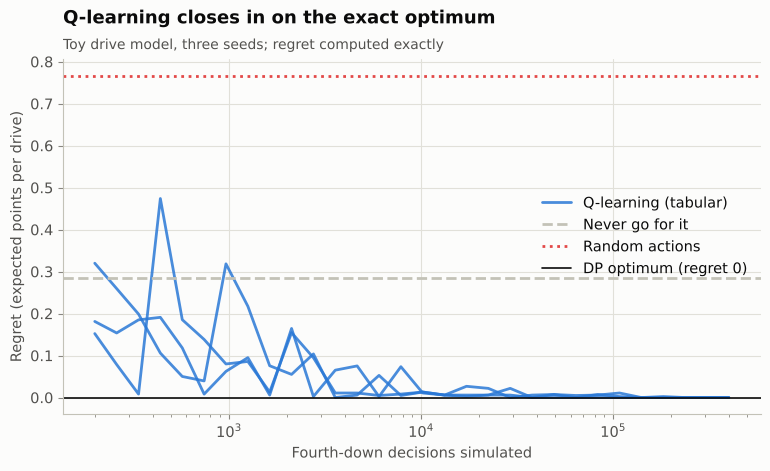

In [6]:
from fourth_and_rl.rl import ALGO_COLORS, ALGO_LABELS

fig, ax = plt.subplots(figsize=(9, 4.6))
for seed, c in curves.items():
    ax.plot(c[:, 0], c[:, 1], color=ALGO_COLORS["q_learning"], alpha=0.85,
            label=ALGO_LABELS["q_learning"] if seed == 0 else None)
ax.axhline(baselines["never_go"], color=ALGO_COLORS["never_go"], ls="--", label=ALGO_LABELS["never_go"])
ax.axhline(baselines["random"], color=ALGO_COLORS["random"], ls=":", label=ALGO_LABELS["random"])
ax.axhline(0, color=ALGO_COLORS["optimal"], lw=1.2, label=ALGO_LABELS["optimal"] + " (regret 0)")
ax.set_xscale("log")
ax.set_xlabel("Fourth-down decisions simulated")
ax.set_ylabel("Regret (expected points per drive)")
style.title(ax, "Q-learning closes in on the exact optimum", "Toy drive model, three seeds; regret computed exactly")
ax.legend(loc="center right")
plt.show()

**What to notice.** Regret falls fast at first and then slowly: the last decisions to be learned are the close calls, where the two best actions are worth almost the same, not the rare states (the M5 notes measure this on the real model). The toy is small, so the agent gets close to zero; on the real single-drive model tabular Q-learning was still at about 0.015 points per drive after 6 million decisions (mean of five seeds, M5).

Limits of this notebook: the bundle covers a fixed grid only; the RL part uses a toy model, not the football-sized one; every model limit listed in the app footer applies to the numbers in section 2.